# 02 - Exploratory Data Analysis (EDA)

Now that the data is clean, I explore it to understand how the business is doing and to find answers to questions a manager could ask, like:

- How much do we sell and how much do we earn? Are we growing?
- When do we sell more (months, days of the week)?
- Which categories and products bring the most revenue and the most profit?
- Are discounts helping or hurting the business?
- Who are our customers and where are they?
- How are shipping and returns performing?

**Sections:**
1. Business overview (KPIs)
2. Distribution of the main variables
3. Sales over time
4. Products and categories
5. Discounts
6. Customers and geography
7. Shipping and returns
8. Correlation between numeric variables
9. Key findings and recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# fixed colors, so each category always has the same color in every chart
MAIN_COLOR = "#2a78d6"
CATEGORY_COLORS = {"Furniture": "#2a78d6", "Office Supplies": "#eb6834", "Technology": "#1baf7a"}
YEAR_COLORS = {2023: "#a3a3a3", 2024: "#2a78d6"}

# formatter to show axis values like 1.2M or 300K
def money_format(x, pos):
    if abs(x) >= 1_000_000:
        return f"{x / 1_000_000:.1f}M"
    if abs(x) >= 1_000:
        return f"{x / 1_000:.0f}K"
    return f"{x:.0f}"

money = mtick.FuncFormatter(money_format)

In [2]:
df = pd.read_csv("../data/processed/sales_clean.csv", parse_dates=["order_date", "ship_date", "deliver_date"])
print(df.shape)
df.head(3)

(80915, 33)


,order_id,order_date,ship_date,deliver_date,ship_mode,order_status,customer_id,customer_name,segment,city,...,payment_method,days_to_ship,days_to_deliver,is_returned,order_year,order_month,order_quarter,year_month,weekday,total_cost
0,ORD-000001,2023-01-01,2023-01-02,2023-01-04,First Class,Delivered,CUST-05329,Mrs. Dawn Hawkins,Consumer,Lake Angela,...,Credit Card,1,3,0,2023,1,1,2023-01,Sunday,80
1,ORD-000002,2023-01-01,2023-01-02,2023-01-05,Second Class,Delivered,CUST-01501,Jacob Duran,Consumer,Andersonland,...,Credit Card,1,4,0,2023,1,1,2023-01,Sunday,2
2,ORD-000003,2023-01-01,2023-01-02,2023-01-09,Standard Class,Delivered,CUST-02180,Christine Williams,Corporate,Port Amanda,...,Credit Card,1,8,0,2023,1,1,2023-01,Sunday,2


## 1. Business overview (KPIs)

Remember that each row is one product inside an order. So to count orders I use `order_id` unique values,
and to count customers I use `customer_id` unique values.

In [3]:
total_revenue = df["sales"].sum()
total_profit = df["profit"].sum()
n_orders = df["order_id"].nunique()
n_customers = df["customer_id"].nunique()

print(f"Total revenue:        {total_revenue:>14,.0f} USD")
print(f"Total profit:         {total_profit:>14,.0f} USD")
print(f"Profit margin:        {total_profit / total_revenue:>14.1%}")
print(f"Number of orders:     {n_orders:>14,}")
print(f"Number of customers:  {n_customers:>14,}")
print(f"Average order value:  {total_revenue / n_orders:>14,.2f} USD")
print(f"Units sold:           {df['quantity'].sum():>14,}")
print(f"Return rate (lines):  {df['is_returned'].mean():>14.1%}")
print(f"Revenue of returned lines: {df.loc[df['is_returned'] == 1, 'sales'].sum():>9,.0f} USD")

Total revenue:            35,733,464 USD
Total profit:             10,278,012 USD
Profit margin:                 28.8%
Number of orders:             60,000
Number of customers:           7,962
Average order value:          595.56 USD
Units sold:                  142,224
Return rate (lines):            6.8%
Revenue of returned lines: 2,097,751 USD


**Note on the margin:** I calculate it as total profit / total revenue. The average of the `profit_margin` column would give a different (wrong) value, because it gives the same weight to a 7 USD pen and a 1,299 USD laptop.

In [4]:
# the same KPIs, year by year
yearly = df.groupby("order_year").agg(
    revenue=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique"),
    customers=("customer_id", "nunique"),
)
yearly["margin_%"] = yearly["profit"] / yearly["revenue"] * 100
yearly["avg_order_value"] = yearly["revenue"] / yearly["orders"]

# growth from 2023 to 2024
growth = (yearly.loc[2024] / yearly.loc[2023] - 1) * 100
yearly.loc["growth_%"] = growth

yearly.round(1)

,revenue,profit,orders,customers,margin_%,avg_order_value
order_year,,,,,,
2023,17902315.2,5154851.2,30066.0,7547.0,28.8,595.4
2024,17831148.5,5123160.5,29934.0,7548.0,28.7,595.7
growth_%,-0.4,-0.6,-0.4,0.0,-0.2,0.0


## 2. Distribution of the main variables

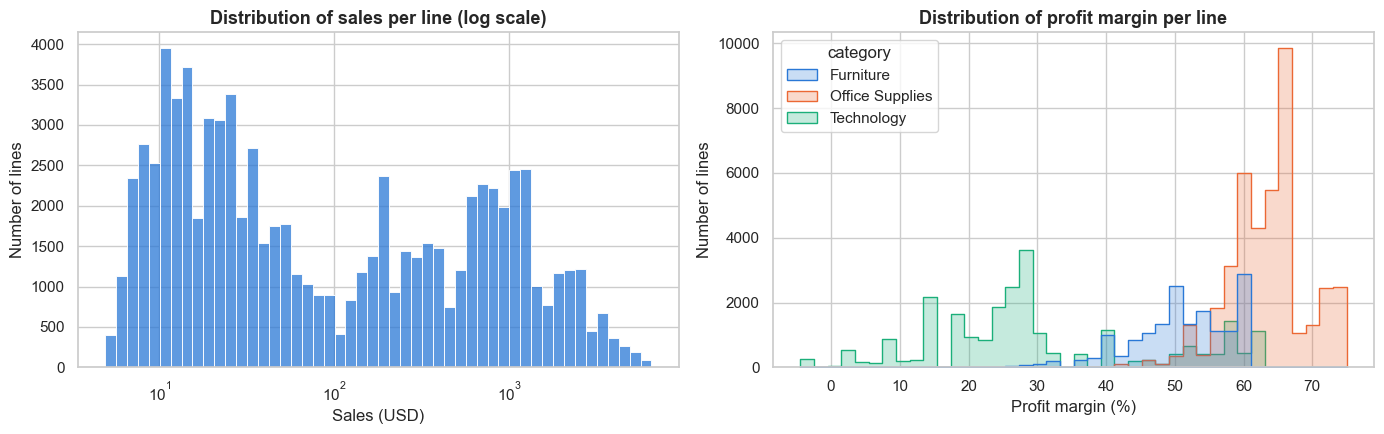

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# with a normal scale almost everything is squeezed on the left, so I use a log scale
sns.histplot(df["sales"], bins=50, log_scale=True, color=MAIN_COLOR, ax=axes[0])
axes[0].set_title("Distribution of sales per line (log scale)")
axes[0].set_xlabel("Sales (USD)")
axes[0].set_ylabel("Number of lines")

sns.histplot(data=df, x="profit_margin", hue="category", palette=CATEGORY_COLORS,
             bins=40, element="step", ax=axes[1])
axes[1].set_title("Distribution of profit margin per line")
axes[1].set_xlabel("Profit margin (%)")
axes[1].set_ylabel("Number of lines")

plt.tight_layout()
plt.show()

- Sales per line are very **right-skewed**: most lines are cheap office supplies (under 50 USD) and a smaller group of tech and furniture lines are worth hundreds or thousands.
  The log scale shows two "groups" of products: cheap and expensive.
- The margin depends a lot on the category: **Office Supplies have the highest margins** (60-75%), Technology the lowest (some lines even below 0).

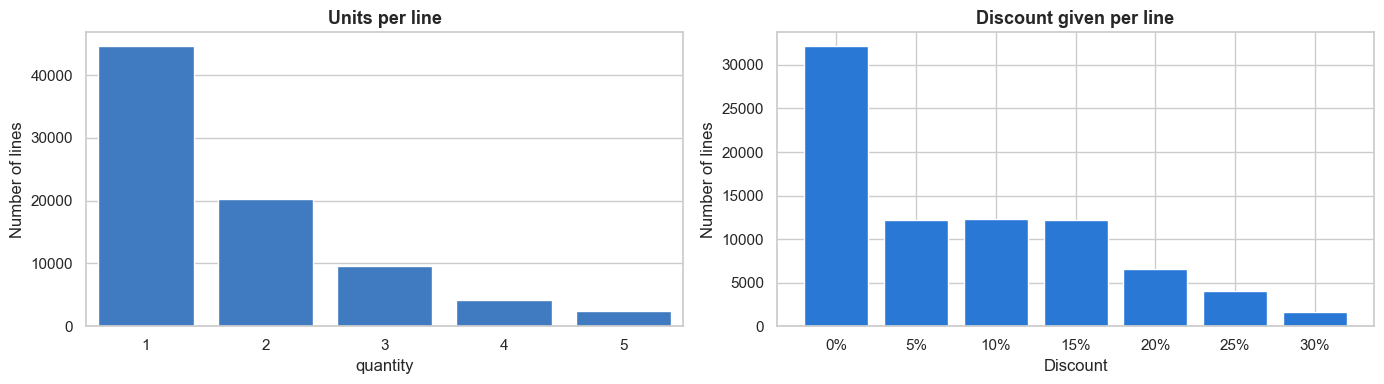

Lines with 1 unit: 55%
Lines with some discount: 60%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(data=df, x="quantity", color=MAIN_COLOR, ax=axes[0])
axes[0].set_title("Units per line")
axes[0].set_ylabel("Number of lines")

discount_counts = df["discount"].value_counts().sort_index()
axes[1].bar([f"{d:.0%}" for d in discount_counts.index], discount_counts.values, color=MAIN_COLOR)
axes[1].set_title("Discount given per line")
axes[1].set_xlabel("Discount")
axes[1].set_ylabel("Number of lines")

plt.tight_layout()
plt.show()

print(f"Lines with 1 unit: {(df['quantity'] == 1).mean():.0%}")
print(f"Lines with some discount: {(df['discount'] > 0).mean():.0%}")

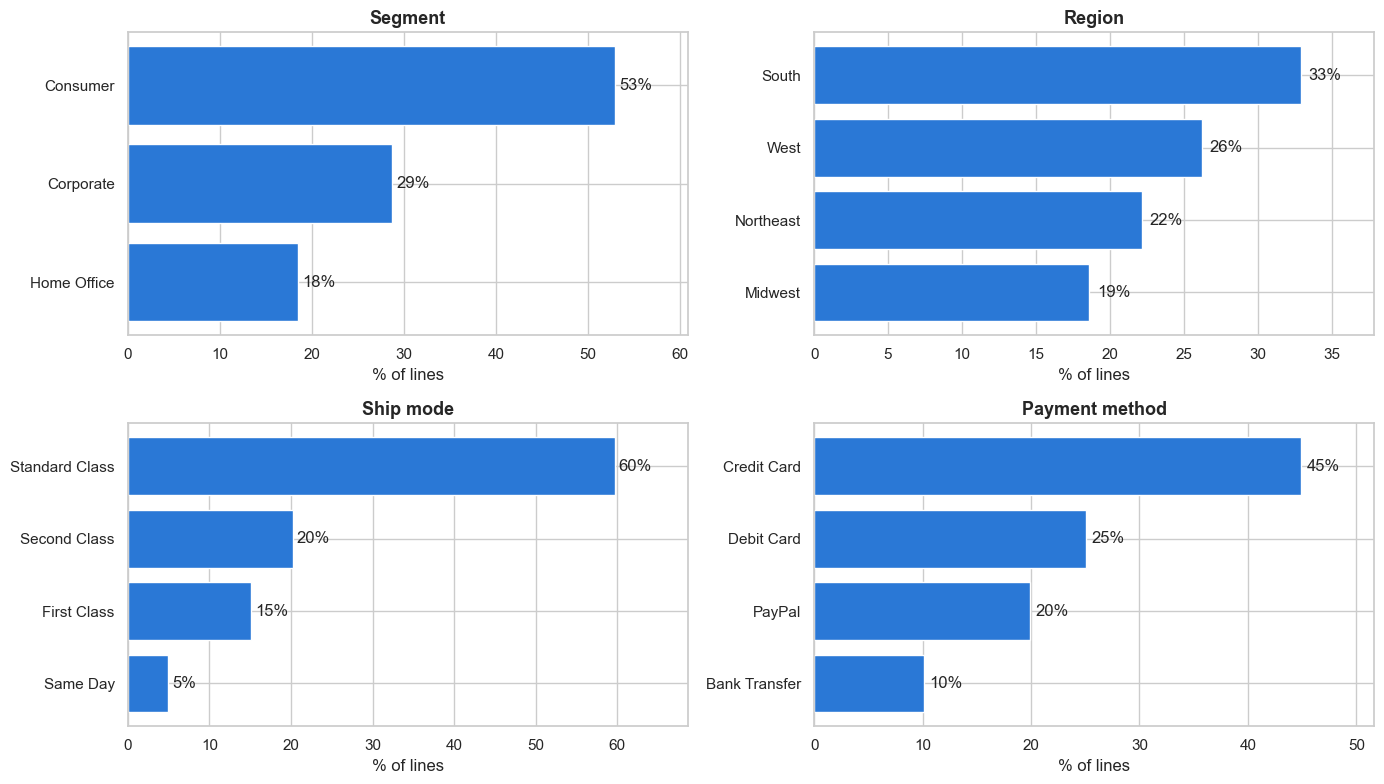

In [7]:
# how the lines are split in the main categorical columns
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.flatten(), ["segment", "region", "ship_mode", "payment_method"]):
    shares = df[col].value_counts(normalize=True) * 100
    ax.barh(shares.index, shares.values, color=MAIN_COLOR)
    ax.invert_yaxis()
    ax.set_xlim(0, shares.max() * 1.15)   # space for the labels
    ax.set_title(col.replace("_", " ").capitalize())
    ax.set_xlabel("% of lines")
    for i, v in enumerate(shares.values):
        ax.text(v + 0.5, i, f"{v:.0f}%", va="center")

plt.tight_layout()
plt.show()

- More than half of the lines come from **Consumer** customers, and the **South** is the biggest region.
- **Standard Class** is by far the most used shipping mode (around 60%).
- **Credit card** is the most used payment method.

## 3. Sales over time

**Question: Is the business growing? Are there months when we sell more?**

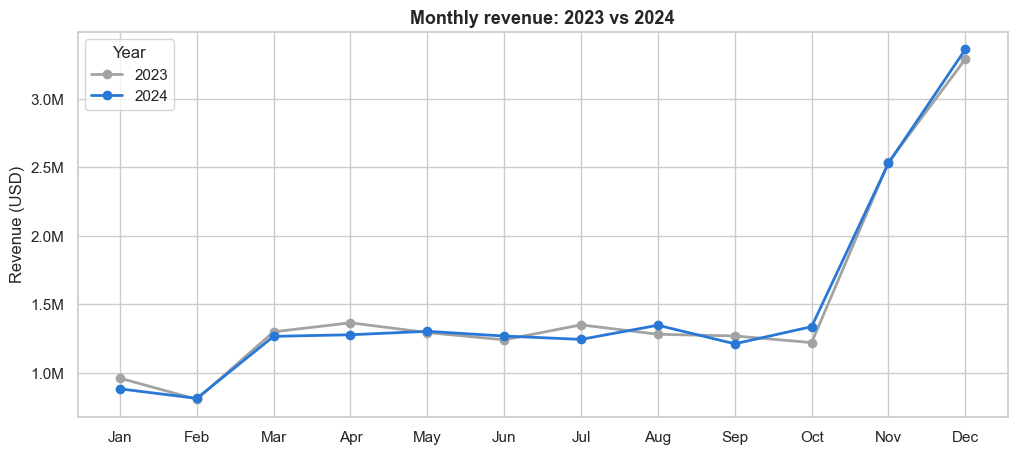

In [8]:
monthly = df.groupby(["order_year", "order_month"])["sales"].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
for year in [2023, 2024]:
    data = monthly[monthly["order_year"] == year]
    ax.plot(data["order_month"], data["sales"], marker="o", linewidth=2,
            color=YEAR_COLORS[year], label=str(year))

ax.set_title("Monthly revenue: 2023 vs 2024")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Revenue (USD)")
ax.yaxis.set_major_formatter(money)
ax.legend(title="Year")

plt.savefig("../images/monthly_revenue.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
# how much of the year's revenue comes from each quarter?
quarter_share = df.pivot_table(index="order_quarter", columns="order_year", values="sales", aggfunc="sum")
quarter_share = quarter_share / quarter_share.sum() * 100
quarter_share.round(1)

order_year,2023,2024
order_quarter,,
1,17.1,16.6
2,21.8,21.6
3,21.8,21.3
4,39.3,40.5


- The two years are **almost identical**: the business is **not growing**, revenue is flat from 2023 to 2024 (-0.4%).
- There is a very strong **seasonality**: November sells about **2x** a normal month and December about **2.6x** (Black Friday + Christmas).
  **Q4 alone is around 40% of the year's revenue**.
- January and February are the weakest months (30-35% below a normal month), right after the peak.

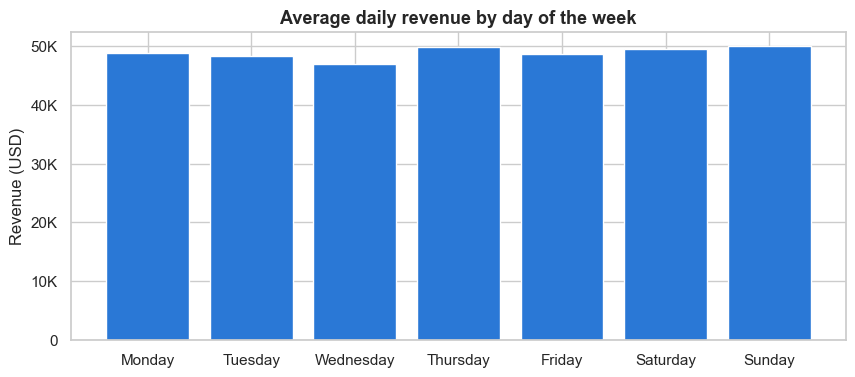

weekday
Monday       48795.0
Tuesday      48327.0
Wednesday    47039.0
Thursday     49808.0
Friday       48640.0
Saturday     49591.0
Sunday       49976.0
Name: sales, dtype: float64

In [10]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# average revenue per day for each weekday (there is not the same number of Mondays and Sundays in 2 years)
daily = df.groupby(["order_date", "weekday"])["sales"].sum().reset_index()
weekday_avg = daily.groupby("weekday")["sales"].mean().reindex(weekday_order)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(weekday_avg.index, weekday_avg.values, color=MAIN_COLOR)
ax.set_title("Average daily revenue by day of the week")
ax.set_ylabel("Revenue (USD)")
ax.yaxis.set_major_formatter(money)
plt.show()

weekday_avg.round(0)

There is no big difference between the days of the week, so the day doesn't seem to matter much for this business. The months are much more important.

## 4. Products and categories

**Question: Which categories and products make the most money - in revenue and in profit?**

In [11]:
by_category = df.groupby("category").agg(
    revenue=("sales", "sum"),
    profit=("profit", "sum"),
    units=("quantity", "sum"),
)
by_category["margin_%"] = by_category["profit"] / by_category["revenue"] * 100
by_category["revenue_share_%"] = by_category["revenue"] / by_category["revenue"].sum() * 100
by_category["profit_share_%"] = by_category["profit"] / by_category["profit"].sum() * 100

by_category.sort_values("revenue", ascending=False).round(1)

,revenue,profit,units,margin_%,revenue_share_%,profit_share_%
category,,,,,,
Technology,27634193.2,6166638.2,42876,22.3,77.3,60.0
Furniture,7250606.6,3578291.6,28526,49.4,20.3,34.8
Office Supplies,848664.0,533082.0,70822,62.8,2.4,5.2


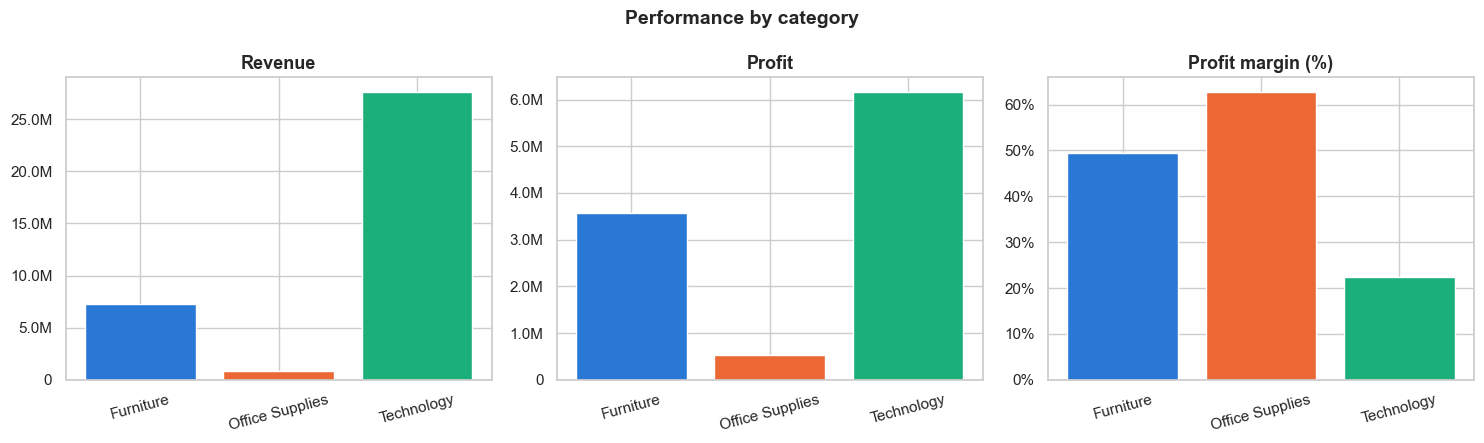

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = [CATEGORY_COLORS[c] for c in by_category.index]

axes[0].bar(by_category.index, by_category["revenue"], color=colors)
axes[0].set_title("Revenue")
axes[0].yaxis.set_major_formatter(money)

axes[1].bar(by_category.index, by_category["profit"], color=colors)
axes[1].set_title("Profit")
axes[1].yaxis.set_major_formatter(money)

axes[2].bar(by_category.index, by_category["margin_%"], color=colors)
axes[2].set_title("Profit margin (%)")
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter())

for ax in axes:
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Performance by category", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../images/category_performance.png", dpi=120, bbox_inches="tight")
plt.show()

This is one of the most important results:
- **Technology is the core of the business**: it's most of the revenue and also most of the profit, even with the lowest margin.
- **Office Supplies** sells the most units and has the best margin, but the products are so cheap that the total profit is small.
- **Furniture** is in the middle.

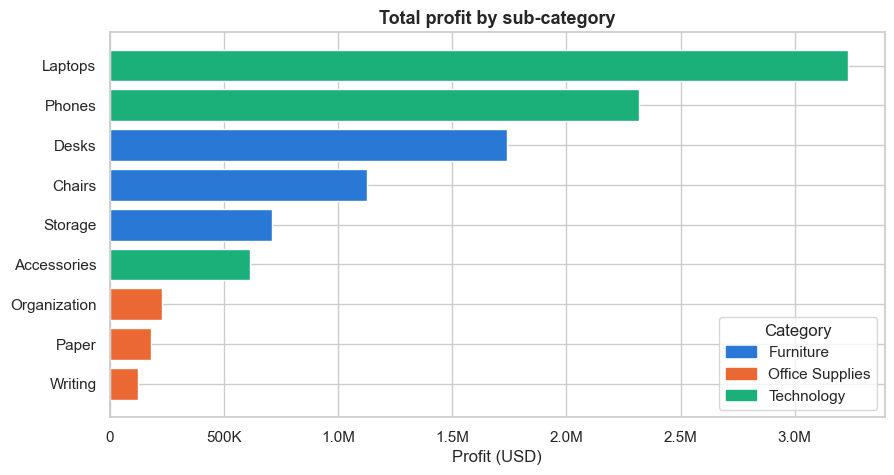

,category,sub_category,revenue,profit,margin_%
7,Technology,Laptops,15593869.3,3232469.3,20.7
8,Technology,Phones,10520068.5,2317708.5,22.0
1,Furniture,Desks,3541777.8,1740637.8,49.1
0,Furniture,Chairs,2454584.0,1128254.0,46.0
2,Furniture,Storage,1254244.8,709399.8,56.6
6,Technology,Accessories,1520255.4,616460.4,40.5
3,Office Supplies,Organization,378320.6,227901.6,60.2
4,Office Supplies,Paper,274308.1,180140.1,65.7
5,Office Supplies,Writing,196035.2,125040.2,63.8


In [13]:
by_subcat = df.groupby(["category", "sub_category"]).agg(revenue=("sales", "sum"), profit=("profit", "sum")).reset_index()
by_subcat["margin_%"] = by_subcat["profit"] / by_subcat["revenue"] * 100
by_subcat = by_subcat.sort_values("profit", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(by_subcat["sub_category"], by_subcat["profit"],
        color=[CATEGORY_COLORS[c] for c in by_subcat["category"]])
ax.set_title("Total profit by sub-category")
ax.set_xlabel("Profit (USD)")
ax.xaxis.set_major_formatter(money)

# simple legend for the category colors
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in CATEGORY_COLORS.values()]
ax.legend(handles, CATEGORY_COLORS.keys(), title="Category", loc="lower right")

plt.show()

by_subcat.sort_values("profit", ascending=False).round(1)

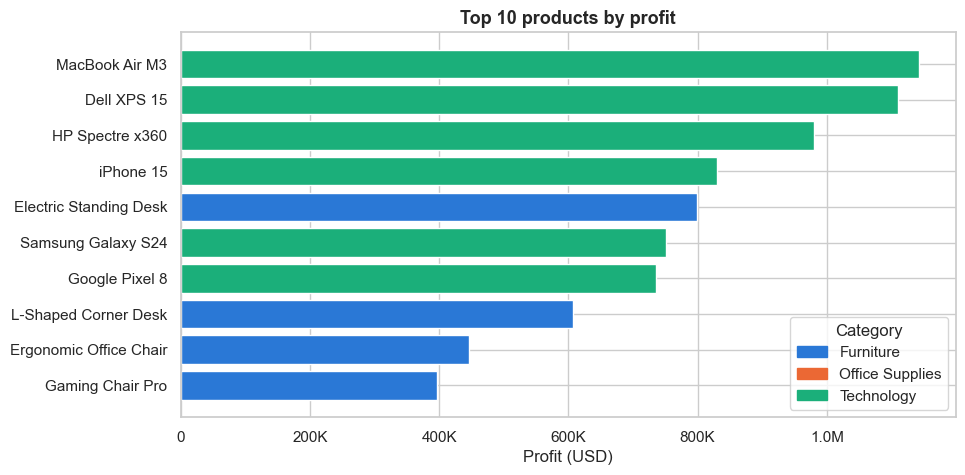

In [14]:
by_product = df.groupby(["product_name", "category"]).agg(
    revenue=("sales", "sum"),
    profit=("profit", "sum"),
    units=("quantity", "sum"),
).reset_index()
by_product["margin_%"] = by_product["profit"] / by_product["revenue"] * 100

top10 = by_product.sort_values("profit", ascending=False).head(10).sort_values("profit")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10["product_name"], top10["profit"], color=[CATEGORY_COLORS[c] for c in top10["category"]])
ax.set_title("Top 10 products by profit")
ax.set_xlabel("Profit (USD)")
ax.xaxis.set_major_formatter(money)
ax.legend(handles, CATEGORY_COLORS.keys(), title="Category", loc="lower right")
plt.savefig("../images/top10_products.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
# and the 5 products that make the least profit
by_product.sort_values("profit").head(5).round(1)

,product_name,category,revenue,profit,units,margin_%
16,Highlighter Set 6 Colors,Office Supplies,50771.7,35027.7,7872,69.0
4,Ballpoint Pens 12pk,Office Supplies,64917.9,41430.9,7829,63.8
22,Sticky Notes 12-Pack,Office Supplies,57493.6,41879.6,7807,72.8
19,Mechanical Pencils 5pk,Office Supplies,80345.6,48581.6,7941,60.5
11,File Folders 50-Pack,Office Supplies,84966.6,54182.6,7696,63.8


- The top of the ranking is dominated by **laptops and phones**: few units sold, but each one gives a lot of profit.
- The products with the lowest profit are pens, sticky notes and paper - high margin, but very low value.

## 5. Discounts

**Question: Are the discounts worth it? Do they make customers buy more?**

In [16]:
by_discount = df.groupby("discount").agg(
    lines=("sales", "count"),
    avg_quantity=("quantity", "mean"),
    revenue=("sales", "sum"),
    profit=("profit", "sum"),
)
by_discount["margin_%"] = by_discount["profit"] / by_discount["revenue"] * 100
by_discount.index = [f"{d:.0%}" for d in by_discount.index]
by_discount.round(2)

,lines,avg_quantity,revenue,profit,margin_%
0%,32136,1.76,15174291.00,5242561.00,34.55
5%,12192,1.75,5654009.55,1756268.55,31.06
10%,12276,1.75,5322680.10,1448831.10,27.22
15%,12140,1.76,5032027.20,1150507.20,22.86
20%,6563,1.75,2556524.00,459307.00,17.97
25%,4020,1.80,1478149.50,184453.50,12.48
30%,1588,1.75,515782.40,36083.40,7.00


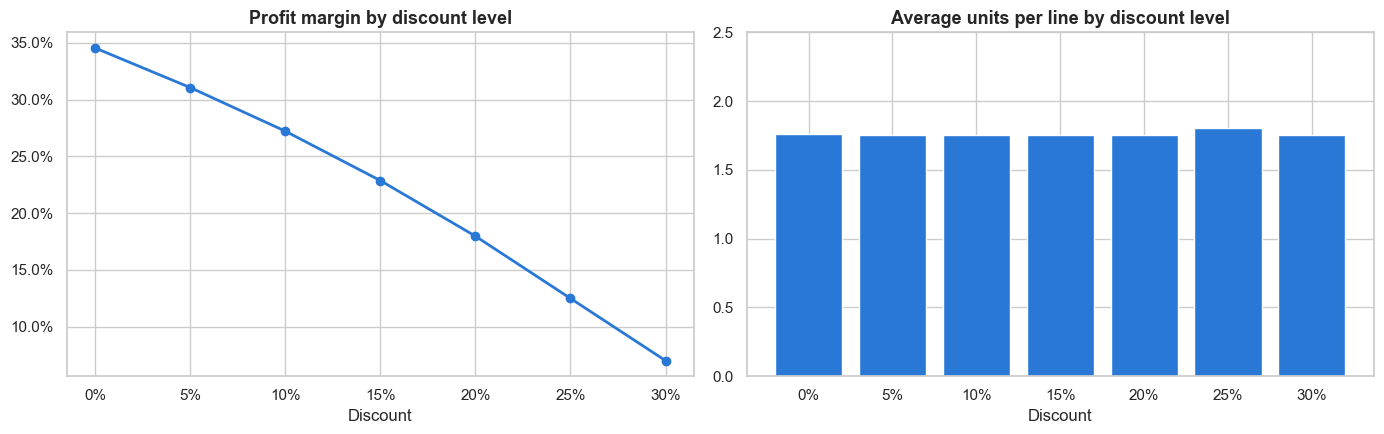

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(by_discount.index, by_discount["margin_%"], marker="o", linewidth=2, color=MAIN_COLOR)
axes[0].set_title("Profit margin by discount level")
axes[0].set_xlabel("Discount")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())

axes[1].bar(by_discount.index, by_discount["avg_quantity"], color=MAIN_COLOR)
axes[1].set_title("Average units per line by discount level")
axes[1].set_xlabel("Discount")
axes[1].set_ylim(0, 2.5)

plt.tight_layout()
plt.savefig("../images/discount_effect.png", dpi=120, bbox_inches="tight")
plt.show()

In [18]:
# Technology has the lowest margin, so check what happens there with high discounts
tech = df[df["category"] == "Technology"]
tech_discount = tech.groupby("discount").agg(revenue=("sales", "sum"), profit=("profit", "sum"))
tech_discount["margin_%"] = tech_discount["profit"] / tech_discount["revenue"] * 100
tech_discount.round(1)

,revenue,profit,margin_%
discount,,,
0.00,11729145.0,3353950.0,28.6
0.05,4362163.4,1081928.4,24.8
0.10,4118061.6,848761.6,20.6
0.15,3902978.2,623538.2,16.0
0.20,1985017.6,212912.6,10.7
0.25,1146963.8,53003.8,4.6
0.30,389863.6,-7456.4,-1.9


In [19]:
loss_lines = df[df["profit"] < 0]
print(f"Lines sold at a loss: {len(loss_lines)}")
print(f"Total money lost on these lines: {loss_lines['profit'].sum():,.0f} USD")
print(f"Revenue from lines with 30% discount: {df.loc[df['discount'] == 0.3, 'sales'].sum():,.0f} USD")

Lines sold at a loss: 305
Total money lost on these lines: -12,485 USD
Revenue from lines with 30% discount: 515,782 USD


- Each extra 5% of discount takes margin away, as expected.
- But the discounts **don't make customers buy more**: the average number of units per line is the same with or without discount.
  So, in this data, discounts reduce profit without bringing extra volume.
- In Technology a **30% discount gives a near-zero (or negative) margin**: every phone and laptop sold with 30% off makes a loss.

## 6. Customers and geography

**Question: Who are our customers, where are they, and how much do the best ones matter?**

In [20]:
by_segment = df.groupby("segment").agg(
    customers=("customer_id", "nunique"),
    orders=("order_id", "nunique"),
    revenue=("sales", "sum"),
    profit=("profit", "sum"),
)
by_segment["revenue_share_%"] = by_segment["revenue"] / by_segment["revenue"].sum() * 100
by_segment["avg_order_value"] = by_segment["revenue"] / by_segment["orders"]
by_segment["revenue_per_customer"] = by_segment["revenue"] / by_segment["customers"]
by_segment.round(1)

,customers,orders,revenue,profit,revenue_share_%,avg_order_value,revenue_per_customer
segment,,,,,,,
Consumer,4199,31645,18757982.2,5401476.2,52.5,592.8,4467.2
Corporate,2323,17292,10365115.7,2965662.7,29.0,599.4,4462.0
Home Office,1440,11063,6610365.8,1910872.8,18.5,597.5,4590.5


The segments behave in a similar way per customer and per order - Consumer is the biggest only because it has more customers.

In [21]:
by_region = df.groupby("region").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                      customers=("customer_id", "nunique"))
by_region["margin_%"] = by_region["profit"] / by_region["revenue"] * 100
by_region["revenue_per_customer"] = by_region["revenue"] / by_region["customers"]
by_region.sort_values("revenue", ascending=False).round(1)

,revenue,profit,customers,margin_%,revenue_per_customer
region,,,,,
South,11702874.0,3369173.0,2605,28.8,4492.5
West,9369338.2,2693636.2,2071,28.7,4524.1
Northeast,8024911.6,2311801.6,1805,28.8,4445.9
Midwest,6636340.0,1903401.0,1481,28.7,4481.0


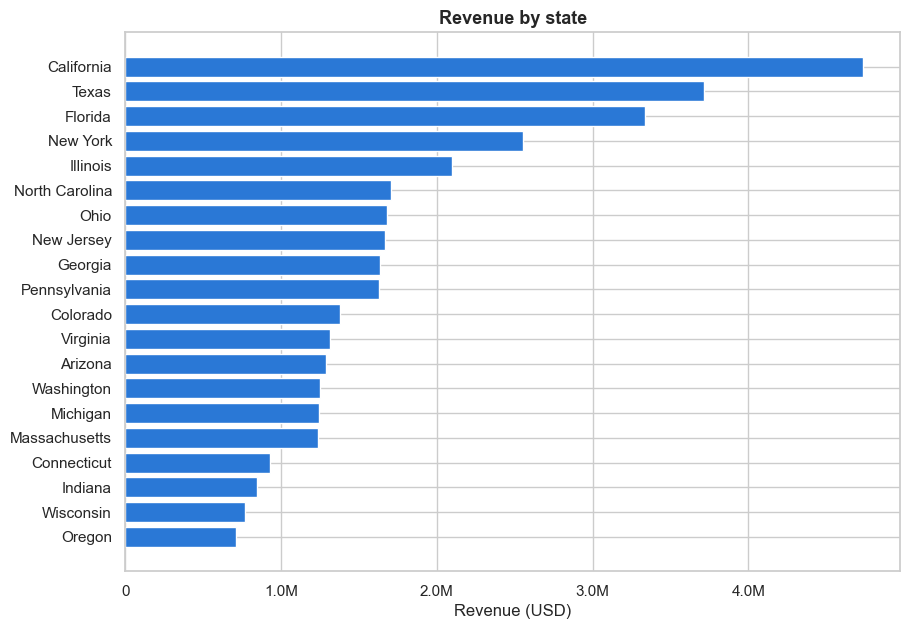

Top 3 states = 33% of revenue


In [22]:
by_state = df.groupby("state")["sales"].sum().sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(by_state.index, by_state.values, color=MAIN_COLOR)
ax.set_title("Revenue by state")
ax.set_xlabel("Revenue (USD)")
ax.xaxis.set_major_formatter(money)
plt.show()

top3_share = by_state.sort_values(ascending=False).head(3).sum() / by_state.sum()
print(f"Top 3 states = {top3_share:.0%} of revenue")

Revenue follows the number of customers in each state: the big states (California, Texas, Florida, New York) lead. The margin is about the same in every region.

In [23]:
customer_stats = df.groupby("customer_id").agg(
    orders=("order_id", "nunique"),
    revenue=("sales", "sum"),
)

print("Orders per customer:")
print(customer_stats["orders"].describe().round(1))
print()
print(f"Customers with only 1 order: {(customer_stats['orders'] == 1).mean():.1%}")

Orders per customer:
count    7962.0
mean        7.5
std         4.8
min         1.0
25%         4.0
50%         6.0
75%        10.0
max        28.0
Name: orders, dtype: float64

Customers with only 1 order: 2.2%


The top 20% customers generate 48% of the revenue


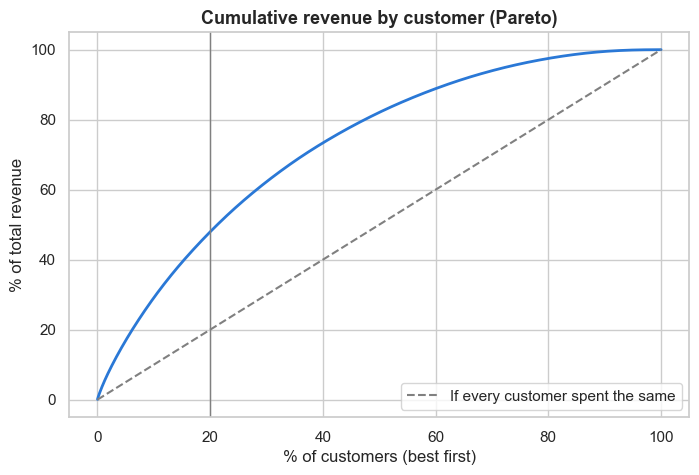

In [24]:
# Pareto analysis: what % of the revenue comes from the best customers?
customer_stats = customer_stats.sort_values("revenue", ascending=False)
customer_stats["cumulative_share"] = customer_stats["revenue"].cumsum() / customer_stats["revenue"].sum() * 100
customer_stats["customer_pct"] = np.arange(1, len(customer_stats) + 1) / len(customer_stats) * 100

top20 = customer_stats.loc[customer_stats["customer_pct"] <= 20, "revenue"].sum() / customer_stats["revenue"].sum()
print(f"The top 20% customers generate {top20:.0%} of the revenue")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(customer_stats["customer_pct"], customer_stats["cumulative_share"], color=MAIN_COLOR, linewidth=2)
ax.plot([0, 100], [0, 100], linestyle="--", color="grey", label="If every customer spent the same")
ax.axvline(20, color="grey", linewidth=1)
ax.set_title("Cumulative revenue by customer (Pareto)")
ax.set_xlabel("% of customers (best first)")
ax.set_ylabel("% of total revenue")
ax.legend()
plt.show()

- Customers are **very loyal**: almost all of them ordered more than once in the 2 years (on average around 7-8 orders each).
- The **top 20% customers generate almost half (48%) of the revenue**. It's not as extreme as the classic 80/20 rule,
  but it means a small group of customers (the ones buying laptops and phones) is worth a lot more than the average one.

## 7. Shipping and returns

**Question: How long do deliveries take, and what is being returned?**

In [25]:
# one row per order for the shipping analysis (ship mode and dates are order-level)
orders = df.drop_duplicates("order_id")

shipping = orders.groupby("ship_mode").agg(
    orders=("order_id", "count"),
    avg_days_to_ship=("days_to_ship", "mean"),
    avg_days_to_deliver=("days_to_deliver", "mean"),
)
shipping["share_%"] = shipping["orders"] / shipping["orders"].sum() * 100
shipping.sort_values("avg_days_to_deliver").round(2)

,orders,avg_days_to_ship,avg_days_to_deliver,share_%
ship_mode,,,,
Same Day,2987,1.49,2.49,4.98
First Class,9103,1.50,3.50,15.17
Second Class,12160,1.50,5.01,20.27
Standard Class,35750,1.50,7.49,59.58


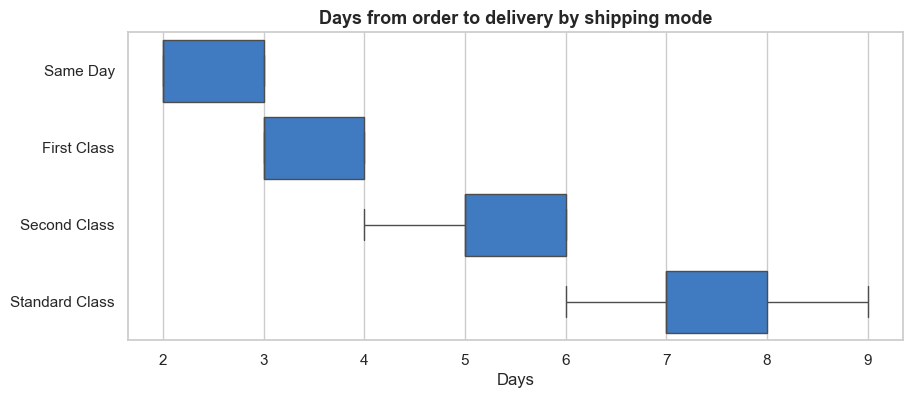

In [26]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=orders, x="days_to_deliver", y="ship_mode", color=MAIN_COLOR,
            order=["Same Day", "First Class", "Second Class", "Standard Class"], ax=ax)
ax.set_title("Days from order to delivery by shipping mode")
ax.set_xlabel("Days")
ax.set_ylabel("")
plt.show()

The shipping modes are clearly different in delivery time (from ~2.5 days for Same Day to ~7.5 for Standard).
But as seen in the cleaning, **Same Day orders are never shipped on the same day**.

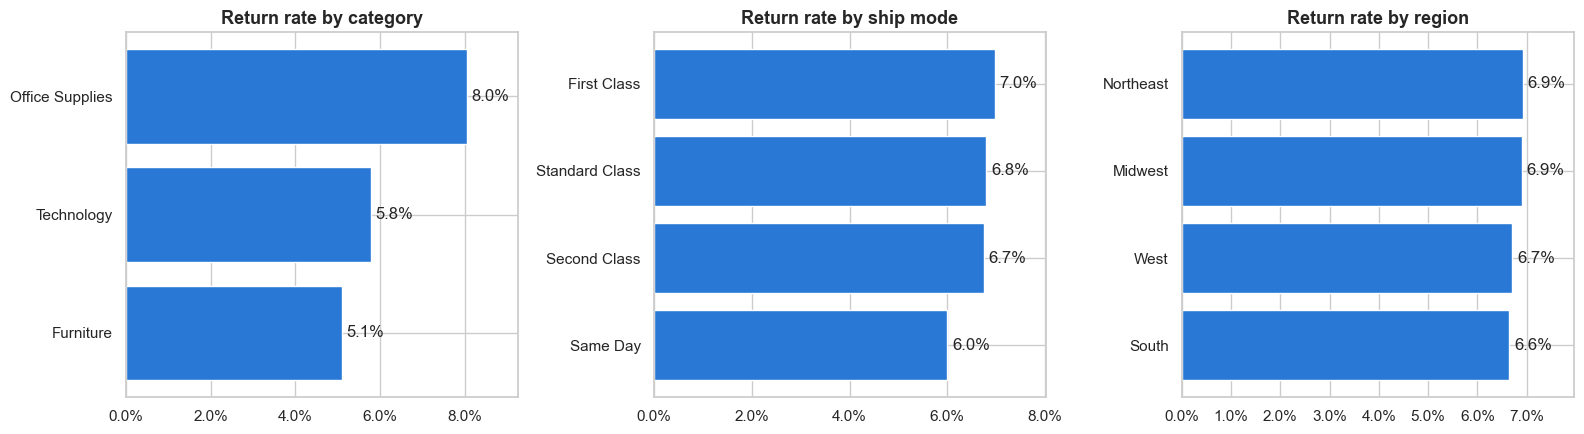

In [27]:
# return rate in each group = average of is_returned (it's 0 or 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, ["category", "ship_mode", "region"]):
    rate = df.groupby(col)["is_returned"].mean().sort_values() * 100
    ax.barh(rate.index, rate.values, color=MAIN_COLOR)
    ax.set_xlim(0, rate.max() * 1.15)   # space for the labels
    ax.set_title(f"Return rate by {col.replace('_', ' ')}")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    for i, v in enumerate(rate.values):
        ax.text(v + 0.1, i, f"{v:.1f}%", va="center")

plt.tight_layout()
plt.savefig("../images/return_rate.png", dpi=120, bbox_inches="tight")
plt.show()

In [28]:
returns_subcat = df.groupby("sub_category").agg(
    return_rate=("is_returned", "mean"),
    returned_revenue=("sales", lambda s: s[df.loc[s.index, "is_returned"] == 1].sum()),
)
returns_subcat["return_rate"] = returns_subcat["return_rate"] * 100
returns_subcat.sort_values("return_rate", ascending=False).round(1)

,return_rate,returned_revenue
sub_category,,
Paper,8.1,23089.8
Writing,8.1,16076.8
Organization,7.9,29632.0
Laptops,6.0,953308.8
Phones,5.8,628299.7
Accessories,5.5,78929.9
Storage,5.2,66489.2
Chairs,5.1,131319.0
Desks,5.0,170606.0


In [29]:
returned_revenue = df.loc[df["is_returned"] == 1, "sales"].sum()
print(f"Revenue from returned lines: {returned_revenue:,.0f} USD ({returned_revenue / total_revenue:.1%} of total revenue)")

Revenue from returned lines: 2,097,751 USD (5.9% of total revenue)


- **Office Supplies have the highest return rate**, while shipping mode and region make almost no difference.
- In money, though, the returns that matter are in Technology: a returned laptop is worth hundreds of returned pens.

## 8. Correlation between numeric variables

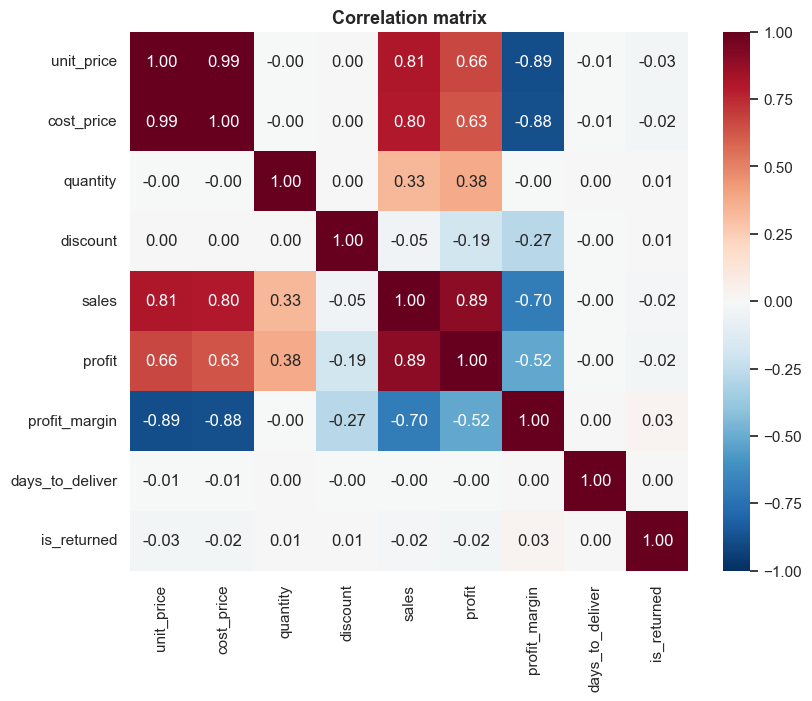

In [30]:
numeric_cols = ["unit_price", "cost_price", "quantity", "discount", "sales", "profit", "profit_margin",
                "days_to_deliver", "is_returned"]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

- `sales`, `profit`, `unit_price` and `cost_price` are strongly correlated - expected, since sales and profit are calculated from the prices.
- `profit_margin` is **negatively correlated with price**: expensive products have lower margins.
- `discount` has a negative correlation with margin, and **almost zero with quantity** (confirms that discounts don't increase volume).
- `is_returned` and `days_to_deliver` have no correlation with anything - returns don't seem to be caused by slow delivery.

## 9. Key findings and recommendations

**What the data says:**

1. **The business is stable but not growing.** 35.7M USD revenue and 10.3M USD profit in 2 years (28.8% margin), and 2024 was practically
   the same as 2023 (-0.4% revenue). Same number of customers and same average order value (~596 USD).
2. **Very strong seasonality.** Q4 is ~40% of the yearly revenue; December alone sells 2.6x a normal month. January and February are the weakest months.
3. **Technology pays the bills.** It's 77% of the revenue and 60% of the profit, with the lowest margin (22%). Laptops and phones are the top products.
   Office Supplies have the best margin (63%) but only 2.4% of the revenue.
4. **Big discounts are destroying profit.** The margin goes from 34.6% with no discount to 7% with 30% off, and discounts **don't increase
   the quantity bought** (1.75 units per line in every discount level). In Technology, a 30% discount means selling at a loss.
5. **Loyal customers, with some concentration.** Only 2.2% of customers ordered just once (median of 6 orders per customer).
   The top 20% customers generate 48% of the revenue.
6. **Segments and regions behave the same way.** Consumer, Corporate and Home Office spend about the same per customer, and all regions have a ~28.8% margin.
   The differences in revenue only come from the number of customers in each group.
7. **Returns are 6.8% of the lines (2.1M USD of revenue).** Office Supplies have the highest return rate (~8%), but in money the biggest losses
   come from laptops and phones. Shipping mode, region and delivery time don't explain the returns.
8. **"Same Day" shipping is not same day** - it ships in 1-2 days, like every other mode.

**Recommendations:**

- **Review the discount policy**, especially in Technology: cap discounts at 15-20% for laptops and phones. Since discounts don't bring more volume,
  this would recover margin without losing sales.
- **Prepare for Q4**: stock, logistics and marketing should be planned around November/December. Consider campaigns in January/February to
  soften the drop after the peak.
- **Grow the business** - the data shows a stable but stagnant company. Possible paths: get new customers (in the SQL notebook, Q11 shows that
  almost no new customers were acquired in 2024) and
  push accessories/furniture together with tech purchases (cross-selling) to increase the order value.
- **Take care of the top customers** (loyalty program, account managers for Corporate), since 20% of them bring almost half of the revenue.
- **Investigate the returns in Office Supplies** (quality? wrong product descriptions?) and **fix or rename the "Same Day" service**.

**Limitations:** the dataset is fictional, has only 2 years (hard to confirm a trend), and has no marketing, stock or customer satisfaction data,
so the reasons behind returns and the effect of discounts can only be partially explained.

Next: [03_sql_analysis.ipynb](03_sql_analysis.ipynb)